# Task 3: Diarization + ASR pipeline with clinical roles

Sahil al Farib, AIMScribe RA (Speech AI) assessment.

```
audio → 16 kHz mono → community-1 → turns → VAD + IndicConformer 600M → roles
Doctor [00:05–00:08]: আপনার কী সমস্যা হচ্ছে?
```

| Step | Result checked |
|---|---|
| 1. Role rule tests | 5/5 + 1 known failure |
| 2. My real consultations A + B | DER 2.7, CER 6.8, roles 2/2 |
| 3. 6 synthetic consultations, before vs after | DER, role error, roles right |
| 4. Model choice | |
| 5. Your own audio | |

Runtime on a T4: ~30 min.

## Setup

1. Runtime → Change runtime type → **T4 GPU**.
2. Add your Hugging Face token to Colab **Secrets** as `HF_TOKEN`.
3. Accept the terms of these models / datasets with that account: [pyannote/speaker-diarization-community-1](https://huggingface.co/pyannote/speaker-diarization-community-1), [pyannote/speaker-diarization-3.1](https://huggingface.co/pyannote/speaker-diarization-3.1), [pyannote/segmentation-3.0](https://huggingface.co/pyannote/segmentation-3.0), [ai4bharat/indic-conformer-600m-multilingual](https://huggingface.co/ai4bharat/indic-conformer-600m-multilingual).

Then Runtime → Run all. The code is cloned from GitHub; models and public data are downloaded.

Each step re-runs an experiment and `check(...)` compares the new number with the submitted one (kept in
`/content/submitted_results`). The table at the end lists all checks. If the runtime disconnects, run all again:
finished steps are skipped.

In [1]:
REPO_URL = "https://github.com/sahilaf/Aimscribe"

import filecmp, json, os, re, shutil, subprocess, zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Audio, Image, Markdown, display
from google.colab import userdata

REPO, DATA = "/content/aimscribe", "/content/aimscribe_data"     # code + labels | audio + models
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, REPO], check=True)
os.makedirs(DATA, exist_ok=True)
os.environ.update(HF_TOKEN=userdata.get("HF_TOKEN"), AIMSCRIBE_DATA=DATA)
SUB, NEW = "/content/submitted_results", f"{REPO}/results"
if not os.path.exists(SUB):
    shutil.copytree(NEW, SUB)                                     # untouched copy of the submitted results
def sh(cmd, tail=None):
    """Run a shell command from the repository root; stop the notebook if it fails.
    tail=N prints only the last N lines (long runs). Library warnings are filtered out."""
    p = subprocess.run(cmd, shell=True, executable="/bin/bash", cwd=REPO, text=True, env=dict(os.environ, MPLBACKEND="Agg"),
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = [l for l in p.stdout.splitlines() if not re.search(r"[Ww]arning|warnings\.warn|FRAME_DURATION", l)]
    print("\n".join(lines[-tail:] if tail else lines))
    if p.returncode:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}")


def fresh(task, run, cmd, tail=2):
    """Run `cmd` once for results/<task>/<run>: the submitted output is deleted first, so a check can never pass on
    submitted files; a marker skips the run after a disconnect."""
    marker = f"/content/.done_task3_{run}"
    if not os.path.exists(marker):
        shutil.rmtree(f"{NEW}/task3/{run}", ignore_errors=True)
        sh(cmd, tail=tail)
        Path(marker).touch()


CHECKS = []
def check(what, submitted, reproduced, tol=0.15):
    """Compare a reproduced number with the submitted one (absolute tolerance, same unit)."""
    ok = reproduced is not None and abs(float(reproduced) - float(submitted)) <= tol
    CHECKS.append({"result": what, "submitted": submitted, "reproduced": reproduced, "tolerance": tol,
                   "match": "✓" if ok else "✗"})
    print(f"{'✓' if ok else '✗'}  {what}: submitted {submitted} | reproduced {reproduced}")


def show_images(paths, titles=None, cols=1, width=16, row_h=3.2):
    """Show saved PNG figures inline (one per row by default)."""
    import matplotlib.image as mpimg
    paths = [p for p in paths if os.path.exists(p)]
    rows = -(-len(paths) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(width, row_h * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, p in enumerate(paths):
        ax = axes.flat[i]
        ax.imshow(mpimg.imread(p))
        ax.set_title(titles[i] if titles else Path(p).stem, fontsize=10)
    plt.tight_layout(); plt.show()


sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")

Tesla T4, 15360 MiB


`venv_p4` runs the final pipeline; `venv_eval` runs the baseline variants and scoring.

In [2]:
sh("pip install -q uv && uv python install 3.12", tail=2)
def venv(name, py="3.12"):
    if not os.path.exists(f"/content/{name}/bin/python"):
        sh(f"uv venv -q --seed --python-preference only-managed --python {py} /content/{name}")
    return f"/content/{name}/bin/python"

EVAL = venv("venv_eval")      # laptop pins: torch 2.5.1, pyannote.audio 3.3.2, transformers 4.46.3, onnxruntime 1.20.1
sh(f"uv pip install -q --python {EVAL} torch==2.5.1 torchaudio==2.5.1 --index-url https://download.pytorch.org/whl/cu121")
sh(f"uv pip install -q --python {EVAL} -r requirements.txt -c constraints.txt")
sh(f"{EVAL} -c 'import torch, pyannote.audio, transformers; print(\"eval env OK | torch\", torch.__version__, \"| pyannote\", pyannote.audio.__version__)'")

P4 = venv("venv_p4")          # pyannote.audio 4.0.7 for community-1 (conflicts with the 3.3.2 pins above)
sh(f"uv pip install -q --python {P4} -r envs/requirements-pyannote4.txt")
sh(f"{P4} -c 'import pyannote.audio; print(\"pyannote 4 env OK |\", pyannote.audio.__version__)'")

Installed Python 3.12.15 in 1.30s
 + cpython-3.12.15-linux-x86_64-gnu (python3.12)



  sep="\s+",
  sep="\s+",
  sep="\s+",
  data = pd.read_csv(file_uem, names=names, dtype=dtype, sep="\s+")
  data = pd.read_csv(path, names=names, dtype=dtype, sep="\s+")
  file_trial, sep="\s+", names=["reference", "uri1", "uri2"]
  ctm, names=names, dtype=dtype, sep="\s+"
  mapping, names=names, dtype=dtype, sep="\s+"
eval env OK | torch 2.5.1+cu121 | pyannote 3.3.2


pyannote 4 env OK | 4.0.7


In [3]:
IC = f"{DATA}/models/indic-conformer-600m"   # a plain folder: the ONNX weights refuse the HF cache's symlinks
if not os.path.exists(f"{IC}/model_onnx.py"):
    sh(f"{EVAL} -c \"import os; from huggingface_hub import snapshot_download as d; "
       f"d('ai4bharat/indic-conformer-600m-multilingual', local_dir='{IC}', token=os.environ['HF_TOKEN'])\"", tail=1)
print("IndicConformer 600M ready:", IC)

Fetching 404 files: 100%|██████████| 404/404 [00:29<00:00, 13.48it/s]
IndicConformer 600M ready: /content/aimscribe_data/models/indic-conformer-600m


## 1. Role rules

Decided from what each speaker says over the whole visit, not from who speaks first.

| Role | Cue |
|---|---|
| Doctor | polite 2nd-person verbs, clinical words |
| Attendant | talks about someone else (ওর, উনার, আমার ছেলে) |
| Patient | own symptoms (আমার / আমি) |
| Other | under 2 s of speech |

Several attendants allowed, one patient. Overlapping turns are marked "(overlap)".

In [4]:
sh(f"{EVAL} task3_pipeline/test_roles.py")

PASS  1. patient speaks first: {'S2': 'Doctor', 'S1': 'Patient'}
PASS  2. two attendants + patient + doctor: {'S4': 'Doctor', 'S1': 'Attendant', 'S2': 'Attendant', 'S3': 'Patient'}
PASS  3. silent patient, two attendants: {'S3': 'Doctor', 'S1': 'Attendant', 'S2': 'Attendant'}
PASS  4. speaker with almost no speech: {'S3': 'Other', 'S1': 'Doctor', 'S2': 'Patient'}
PASS  5. noisy ASR spelling (consult_A style): {'S1': 'Doctor', 'S2': 'Patient'}

5/5 scenarios passed

Known weakness (expected to fail):
FAILS as expected  6. patient talks about family, attendant talks about own worry: got {'S3': 'Doctor', 'S1': 'Attendant', 'S2': 'Patient'}, truth {'S1': 'Patient', 'S2': 'Attendant', 'S3': 'Doctor'}


## 2. My real consultations A and B (dev)

Metrics: DER; role error (DER after mapping speakers to roles); role-attributed WER / CER; cpWER / cpCER.

Attendant [00:46–00:48]: স্টুল টেস্ট করাতে হবে
Doctor [00:49–00:54]: এখন না যদি দুই দিনে ভালো না হয় বা পাতলা ভেখার সাথে রক্ত যায় তখন টেস্ট করাবো
Attendant [00:55–00:56]: ঠিক আছে ধন্যবাদ স্যার
}
✓  consult A+B DER% (final pipeline): submitted 2.66 | reproduced 2.66
✓  consult A+B role_error_rate% (final pipeline): submitted 1.18 | reproduced 1.18
✓  consult A+B CER%_role_attributed (final pipeline): submitted 6.8 | reproduced 6.8
✓  consult A+B WER%_role_attributed (final pipeline): submitted 18.4 | reproduced 18.4
✓  consult A+B cpCER% (final pipeline): submitted 6.8 | reproduced 6.8
✓  consult_A: roles correct: submitted 1 | reproduced 1
✓  consult_B: roles correct: submitted 1 | reproduced 1


,DER%,role_error_rate%,WER%_role_attributed,CER%_role_attributed,cpWER%,cpCER%
consult_A,1.61,0.11,20.2,7.1,20.2,7.1
consult_B,4.07,2.61,15.6,6.3,15.6,6.3
OVERALL,2.66,1.18,18.4,6.8,18.4,6.8


### consult_A

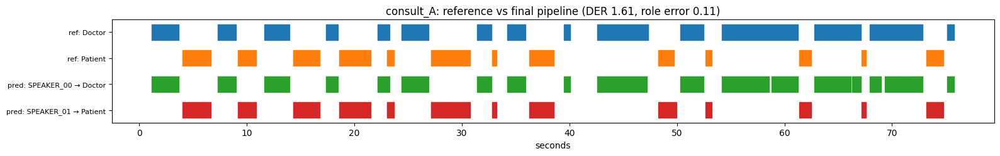

Doctor [00:01–00:03]: আসসালামু আলাইকুম বসুন বলুন আপনার কি সমস্যা হচ্ছে
Patient [00:03–00:06]: ওয়ালাইকুম আসসালাম ডাক্তার সাহেব আমার তিন দিন ধরে জম
Doctor [00:07–00:08]: জ্বর কত ছিল মেপেছিলেন
Patient [00:09–00:10]: জি গতকালকে একশো দুই ছিল
Doctor [00:11–00:13]: হম সাথে কাশি অথবা গলা ব্যথা আছে
Patient [00:14–00:16]: হ্যাঁ একটু কাশি আছে আর মাথা টেপর ব্যথা করো
Doctor [00:17–00:18]: কোনো ওষুধ খেয়েছেন
Patient [00:18–00:21]: না এখনও খায়নি শুধু গরম পানি খাচ্ছেন
Doctor [00:22–00:23] (overlap): প্যারাসিটামল ওখানে নেই
Patient [00:23–00:23] (overlap): না
Doctor [00:24–00:26]: আপনার কি ডায়াবেটিক বা হাই ব্লাড প্রেশার আছেন
Patient [00:27–00:30]: প্রেশার একটু হাই থাকে আমি অ্যান্ডোডি পিন ফাইভ মিলিগ্রাম খাই
Doctor [00:31–00:32]: ঠিক আছে শ্বাসকষ্ট হয়
Patient [00:32–00:33]: না
Doctor [00:34–00:35]: বমি অথবা পাতলা বাইখান হয়েছে
Patient [00:36–00:38]: হম গতকাল একবার বমি হয়েছে
Doctor [00:39–00:40]: আচ্ছা
Doctor [00:42–00:47]: এখন ডেঙ্গুর সিজন তাই একটা সি বিসি আর ডেঙ্গুর এনএস ওয়ান টেস্ট করাবেন
Patient [0

### consult_B

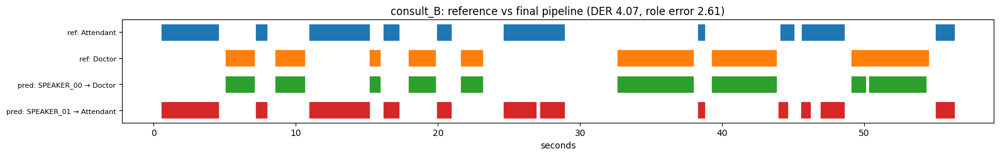

Attendant [00:00–00:04]: স্যার আমার ছেলেকে নিয়ে এসেছি ও গতকাল থেকে পাতলা পায়খানা হচ্ছে
Doctor [00:05–00:07]: আচ্ছা বসুন বাচ্চার বয়স কত
Attendant [00:07–00:07]: চার বছর
Doctor [00:08–00:10]: দিনে কয়েকবার পাতলা পায়খানো হচ্ছে
Attendant [00:10–00:15]: প্রায় ছয় সাতবার আর রাতে একবার বমিও করেছে তারপর থেকে
Doctor [00:15–00:15]: জ্বর আছে
Attendant [00:16–00:17]: হ্যাঁ একটু জ্বর আছে
Doctor [00:17–00:19]: হম পর্শ ঠিক মতো হচ্ছে
Attendant [00:19–00:20]: না কম হচ্ছে
Doctor [00:21–00:23]: কিছু খাওয়ানো হয়েছে কোনো ওষুধ
Attendant [00:24–00:28]: ফার্মাসি থেকে একটা সিরাপ দিয়েছিল ম্যাট্রোনিডাজার মনে হয়
Doctor [00:32–00:37]: ঠিক আছে ওর একটু ডিহাইড্রেশন হচ্ছে প্রতিবার পায়খানার পর আধা কাপ ও স্যালাইন খাওয়াবেন
Attendant [00:38–00:38]: জি
Doctor [00:39–00:43]: আর জিঙ্ক সিরাপ দিচ্ছি দশ দিন খাওয়াবেন অ্যান্টিবায়োটিক এখন দরকার নেই
Attendant [00:43–00:44]: আচ্ছা
Attendant [00:45–00:46]: স্যার
Attendant [00:46–00:48]: স্টুল টেস্ট করাতে হবে
Doctor [00:49–00:54]: এখন না যদি দুই দিনে ভালো না হয় বা পাতলা ভ

In [5]:
fresh("task3", "final_c1", f"{P4} task3_pipeline/pipeline.py --asr_model {IC} --audio data/consultation/audio/consult_A.wav "
                            f"data/consultation/audio/consult_B.wav --out_dir results/task3/final_c1", tail=3)
sh(f"{EVAL} task3_pipeline/evaluate_pipeline.py --run final_c1", tail=1)
s, n = (json.load(open(f"{r}/task3/final_c1/eval.json", encoding="utf-8")) for r in (SUB, NEW))
for k in ["DER%", "role_error_rate%", "CER%_role_attributed", "WER%_role_attributed", "cpCER%"]:
    check(f"consult A+B {k} (final pipeline)", s["OVERALL"][k], n["OVERALL"][k], tol=0.3)
for rec in ["consult_A", "consult_B"]:
    check(f"{rec}: roles correct", int(s[rec]["roles_from_reference_text_correct"]), int(n[rec]["roles_from_reference_text_correct"]), tol=0)
display(pd.DataFrame({k: v for k, v in n.items()}).T[["DER%", "role_error_rate%", "WER%_role_attributed", "CER%_role_attributed",
                                                     "cpWER%", "cpCER%"]])


def read_rttm(path):
    rows = [l.split() for l in open(path) if l.startswith("SPEAKER")]
    return pd.DataFrame({"start": [float(r[3]) for r in rows], "dur": [float(r[4]) for r in rows], "spk": [r[7] for r in rows]})


def timeline(ref_path, hyp_path, roles, title):
    """Reference speakers (top) vs the pipeline's speakers labelled with their predicted role (bottom)."""
    ref, hyp = read_rttm(ref_path), read_rttm(hyp_path)
    lanes = [("ref: " + s, ref[ref.spk == s]) for s in sorted(ref.spk.unique())] + \
            [(f"pred: {s} → {roles.get(s, '?')}", hyp[hyp.spk == s]) for s in sorted(hyp.spk.unique())]
    fig, ax = plt.subplots(figsize=(16, 0.45 * len(lanes) + 0.8))
    for i, (name, d) in enumerate(lanes):
        ax.broken_barh(list(zip(d.start, d.dur)), (len(lanes) - i - 0.8, 0.6), color=f"C{i % 10}")
    ax.set_yticks([len(lanes) - i - 0.5 for i in range(len(lanes))]); ax.set_yticklabels([l[0] for l in lanes], fontsize=8)
    ax.set_xlabel("seconds"); ax.set_title(title); plt.tight_layout(); plt.show()


for rec in ["consult_A", "consult_B"]:
    display(Markdown(f"### {rec}"))
    display(Audio(f"{REPO}/data/consultation/audio/{rec}.wav"))
    timeline(f"{REPO}/data/consultation/rttm/{rec}.rttm", f"{NEW}/task3/final_c1/{rec}.rttm", n[rec]["predicted_roles"],
             f"{rec}: reference vs final pipeline (DER {n[rec]['DER%']}, role error {n[rec]['role_error_rate%']})")
    print(open(f"{NEW}/task3/final_c1/{rec}_transcript.txt", encoding="utf-8").read())

## 3. Six synthetic consultations (test)

S01 patient first · S02 silent patient · S03 5 people · S04 3 speakers · S05 overlap · S06 fan noise

| Run | Diarization | ASR |
|---|---|---|
| `tts_baseline` | pyannote 3.1 | 128 tokens, no VAD |
| `tts_final` | 3.1 + re-clustering | VAD gate |
| `tts_final_c1` | community-1 (final) | VAD gate |

Roles right = same set of roles as the truth and role error < 10 %.

Doctor [00:42–00:43]: ঠিক আছে ধন্যবাদ
}
✓  synthetic consultations DER%, tts_baseline: submitted 23.69 | reproduced 23.69
✓  synthetic consultations role_error_rate%, tts_baseline: submitted 30.39 | reproduced 30.39
✓  synthetic consultations cpCER%, tts_baseline: submitted 31.8 | reproduced 31.8
✓  synthetic consultations roles right (of 6), tts_baseline: submitted 2 | reproduced 2
Doctor [00:42–00:43]: ঠিক আছে ধন্যবাদ
}
✓  synthetic consultations DER%, tts_final: submitted 16.09 | reproduced 16.09
✓  synthetic consultations role_error_rate%, tts_final: submitted 23.59 | reproduced 23.59
✓  synthetic consultations cpCER%, tts_final: submitted 17.8 | reproduced 17.8
✓  synthetic consultations roles right (of 6), tts_final: submitted 4 | reproduced 4
Patient [00:42–00:43]: ধন্যবাদ
}
✓  synthetic consultations DER%, tts_final_c1: submitted 22.94 | reproduced 22.94
✓  synthetic consultations role_error_rate%, tts_final_c1: submitted 21.11 | reproduced 21.11
✓  synthetic consultations cpCE

,DER%,role_error_rate%,CER%_all_text,cpCER%,roles right
run,,,,,
tts_baseline,23.69,30.39,6.9,31.8,2/6
tts_final,16.09,23.59,6.8,17.8,4/6
tts_final_c1,22.94,21.11,7.1,31.5,3/6


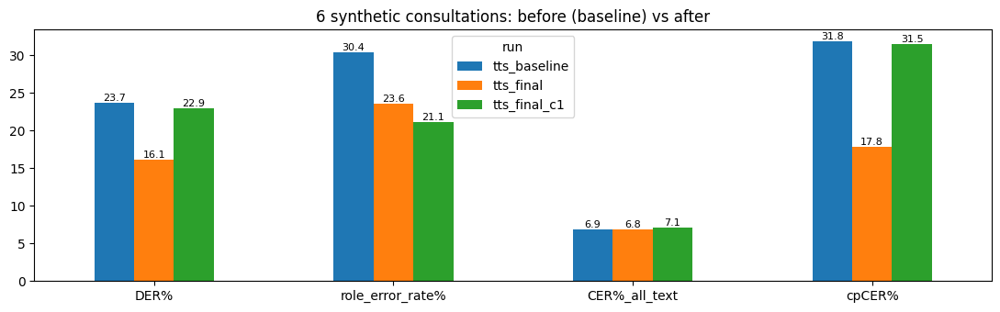

**DER per consultation**

,tts_baseline,tts_final,tts_final_c1
S01,18.46,10.93,11.08
S02,10.75,10.75,10.75
S03,35.36,17.81,35.83
S04,26.38,12.67,36.26
S05,6.69,6.69,6.69
S06,42.53,37.62,33.70


In [6]:
os.makedirs(f"{DATA}/tts_consultation", exist_ok=True)
for f in Path(f"{REPO}/data/tts_consultation/audio").glob("*.wav"):
    shutil.copy(f, f"{DATA}/tts_consultation/")
runs = {"tts_baseline": f"{EVAL} task3_pipeline/pipeline.py --baseline",
        "tts_final": f"{EVAL} task3_pipeline/pipeline.py --diarizer pyannote31_recluster",
        "tts_final_c1": f"{P4} task3_pipeline/pipeline.py"}
def roles_right(ev):
    base = lambda r: re.sub(r"[\s_]*\d+$", "", r)
    return sum(1 for k, v in ev.items() if k != "OVERALL" and {base(r) for r in v["true_roles"].values()} ==
               {base(r) for r in v["predicted_roles"].values()} and v["role_error_rate%"] < 10)
rows = []
for run, cmd in runs.items():
    fresh("task3", run, f"{cmd} --asr_model {IC} --audio {DATA}/tts_consultation/S0*.wav --out_dir results/task3/{run}", tail=1)
    sh(f"{EVAL} task3_pipeline/evaluate_pipeline.py --run {run} --set tts_consultation", tail=1)
    s, n = (json.load(open(f"{r}/task3/{run}/eval.json", encoding="utf-8")) for r in (SUB, NEW))
    for k in ["DER%", "role_error_rate%", "cpCER%"]:
        check(f"synthetic consultations {k}, {run}", s["OVERALL"][k], n["OVERALL"][k], tol=0.5)
    check(f"synthetic consultations roles right (of 6), {run}", roles_right(s), roles_right(n), tol=0)
    rows.append({"run": run, **{k: n["OVERALL"][k] for k in ["DER%", "role_error_rate%", "CER%_all_text", "cpCER%"]},
                 "roles right": f"{roles_right(n)}/6"})
res = pd.DataFrame(rows).set_index("run")
display(res)
ax = res[["DER%", "role_error_rate%", "CER%_all_text", "cpCER%"]].T.plot.bar(rot=0, figsize=(11, 3.5),
     title="6 synthetic consultations: before (baseline) vs after")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout(); plt.show()
per = pd.DataFrame({run: {rec: json.load(open(f"{NEW}/task3/{run}/eval.json", encoding="utf-8"))[rec]["DER%"]
                          for rec in ["S01", "S02", "S03", "S04", "S05", "S06"]} for run in runs})
display(Markdown("**DER per consultation**")); display(per)

### S01: patient speaks first
true roles: ['Doctor', 'Patient'] | predicted: {'SPEAKER_01': 'Patient', 'SPEAKER_00': 'Doctor'} | role error 4.62 %

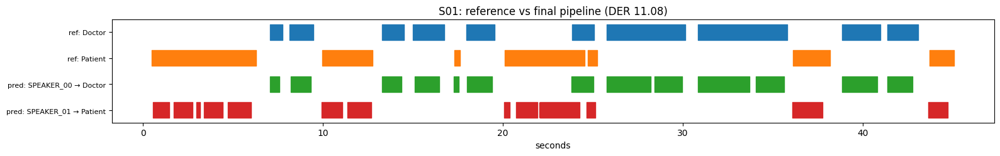

Patient [00:00–00:06]: ডাক্তার সাহেব আমার কয়েকদিন ধরে খুব শ্বাসকষ্ট হচ্ছে বিশেষ করে রাতে
Doctor [00:07–00:07]: আচ্ছা বসু
Doctor [00:08–00:09]: আগে কখনো এমন হয়েছিল
Patient [00:09–00:12]: ছোটবেলা অ্যাজমা ছিল অনেক বছর ভালো ছিলাম
Doctor [00:13–00:14]: এখন কি কাশি আছে
Doctor [00:15–00:16]: বুকে সা শব্দ হয়
Doctor [00:17–00:19]: হ্যাঁ কোনো ইনহেলার ব্যবহার করছেন
Patient [00:20–00:24] (overlap): না শুধু ফার্মেসি থেকে একটা কাশির সিরাপ খাচ্ছি আর
Doctor [00:23–00:25] (overlap): কাজ হবে না
Patient [00:24–00:25] (overlap): জি
Doctor [00:25–00:29]: আমি সালমিটার ফ্রুটি কাসন ইনহালার দিচ্ছি সকালে আর রাতে দুই চাপ করে
Doctor [00:30–00:35]: আর মন্টিডুকাস টেন মিলিগ্রাম রাতে একটা একটা বুকের এক্স রে করাবেন
Patient [00:36–00:37]: ধুলাবালিতে গেলে কী বেশি হয়
Doctor [00:38–00:40]: লাট ঠান্ডা থেকে দূরে থাকবেন
Doctor [00:41–00:42]: দুই সপ্তাহ পরে আবার আসবে
Patient [00:43–00:44]: ঠিক আছে ধন্যবাদ



### S02: silent patient, attendant speaks
true roles: ['Attendant', 'Doctor'] | predicted: {'SPEAKER_00': 'Attendant', 'SPEAKER_01': 'Doctor'} | role error 4.52 %

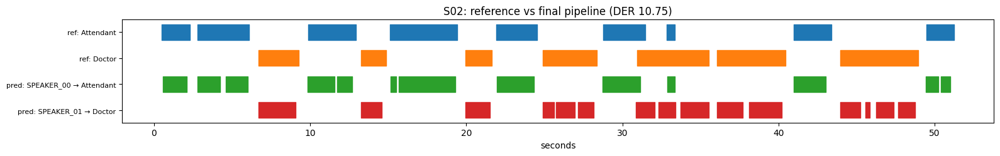

Attendant [00:00–00:02]: আসসালামু অলাইকুম মারম
Attendant [00:02–00:06]: আমার আব্বাকে নিয়ে এসেছি ওনার পায়ে একটা ঘা হয়েছে
Doctor [00:06–00:09]: ওয়ালাইকুম আসসালাম ঘা কতদিনে
Attendant [00:09–00:12]: প্রায় তিন সপ্তাহ শুকাচ্ছে না বরং বড় হচ্ছে
Doctor [00:13–00:14]: ওনার কি ডায়াবেটিস আছে
Attendant [00:15–00:19]: জি দশ বছরের ডায়াবেটিস উনি গ্লিক্লাজাইড আশি মিলিগ্রাম খান
Doctor [00:19–00:21]: সুগার শেষ কবে মেপেছিলেন
Attendant [00:21–00:24]: গত সপ্তাহে খালি পেটে বারো ছিল
Doctor [00:24–00:28]: অনেক বেশি পায়ে কি ব্যথা টের পান না অবশ্য লাগে
Attendant [00:28–00:31] (overlap): উনি বলেন পায়ে তেমন কিছু টের পান
Doctor [00:30–00:33] (overlap): এটা ডায়াবেটিক ফুড ড্রেসিং করতে হবে
Doctor [00:33–00:35]: আর একটা কালচার টেস্ট রাখবি
Doctor [00:36–00:40]: ইনসুলিন শুরু করা দরকার আর এইচবিএন সি টেস্ট করাবেন
Attendant [00:40–00:43]: ইনসুলিন কি সারা জীবন নিতে হবে
Doctor [00:43–00:48]: সেটা রিপোর্ট দেখে বলব পা সবসময় পরিষ্কার আর শুকনো রাখবেন
Attendant [00:49–00:50]: ঠিক আছে ম্যাডাম ধন্যবাদ



### S03: 2 attendants + nurse + child
true roles: ['Attendant', 'Attendant', 'Doctor', 'Other', 'Patient'] | predicted: {'SPEAKER_00': 'Patient', 'SPEAKER_01': 'Doctor'} | role error 41.85 %

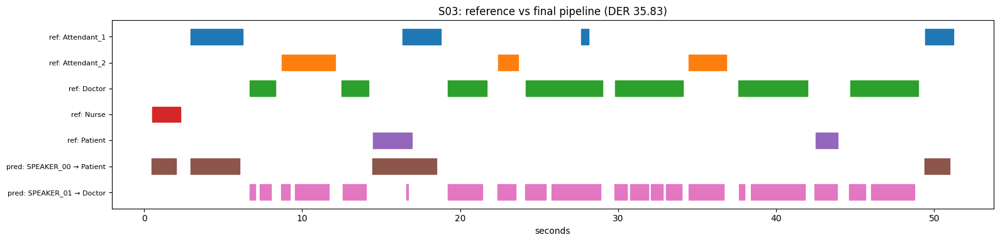

Patient [00:00–00:02]: অরেঞ্জ জোন আসুন সাত নম্বর
Patient [00:02–00:06]: ডাক্তার সাহেব আমার মেয়েটার তিন দিন ধরে জ্বর কিছুতেই কমছে না
Doctor [00:06–00:08]: বসুন ওর বয়স কত
Doctor [00:08–00:11]: আট বছর রাতে জ্বর একশো চার পর্যন্ত উঠেছিল
Doctor [00:12–00:14]: তোমার কোথায় কষ্ট হচ্ছে বলো তো
Patient [00:14–00:18] (overlap): আমার মাথা ব্যথা করে আর গায়ে খুব খেতে যাচ্ছে না শুধু শুয়ে থাকে
Doctor [00:16–00:16] (overlap): হ্যাঁ
Doctor [00:19–00:21]: গায়ে কোনো র্যাস বা লাল ডাগ দেখেছেন
Doctor [00:22–00:23]: না এখনও দেখিনি
Doctor [00:24–00:28]: ডেঙ্গুর সময় চলছে আজকেই সিবি সি আর ডেঙ্গু এনএস ওয়ান টেস্ট করাবেন
Doctor [00:29–00:36]: জ্বরের জন্য প্যারাসিটামল সিরাব দুই চামচ ছয় ঘণ্টা পরপর ব্যথার জন্য কি আইবু প্রোফেন দেওয়া যাবে
Doctor [00:37–00:41]: না ডেঙ্গু না বোঝা পর্যন্ত আইভু প্রোফেন একদম দেবেন না
Doctor [00:42–00:43]: আমি কি স্কুলে যেতে পারবো
Doctor [00:44–00:48]: এই সপ্তাহে না বাসায় বিশ্রাম নেবে আর বেশি করে পানি খাবে
Patient [00:49–00:50]: ঠিক আছে ধন্যবাদ ডাক্তার সাহেব



### S04: 3 speakers
true roles: ['Attendant', 'Doctor', 'Patient'] | predicted: {'SPEAKER_01': 'Attendant', 'SPEAKER_00': 'Doctor'} | role error 34.44 %

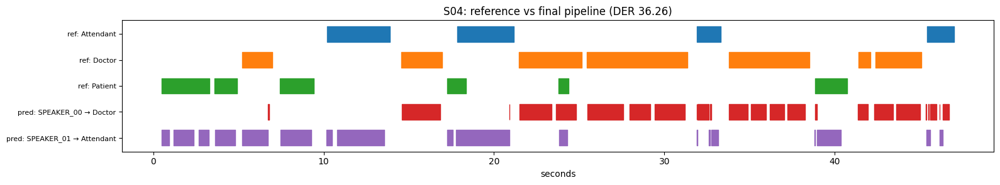

Attendant [00:00–00:06]: বাবা আমার দুই হাঁটুতেই খুব ব্যথা নামাজে বসতে পারি না কতদিন ধরে এমন হচ্ছে খালা
Attendant [00:07–00:09]: অনেকদিন এক বছরের বেশি
Attendant [00:10–00:13]: স্যার আম্মা সিঁড়ি দিয়ে একদম উঠতে পারেন না শীতে আরো বাড়ে
Doctor [00:14–00:16]: হাঁটু কি ফুলে যায় সকালে শক্ত লাগে
Attendant [00:17–00:20]: হ্যাঁ এনি ব্যথার জন্য প্রায় প্রতিদিন ডাইক্লোফেনাক খান
Doctor [00:21–00:24] (overlap): প্রতিদিন ডাইক্লোফেনাক খাওয়া ঠিক না কিডনির ক্ষতি হতে পারে
Attendant [00:23–00:24] (overlap): আচ্ছা
Doctor [00:25–00:31]: এটা অস্টিও আর্থাইটিস মনে হচ্ছে দুই হাঁটুর এক্স রে আর সিরাম ক্রিয়েটিনিন করাবেন
Doctor [00:31–00:32]: ফিওথেপি
Attendant [00:32–00:33]: লাগবে
Doctor [00:33–00:38]: হ্যাঁ ফিজিওথেরাপি আর হালকা ব্যায়াম ব্যথা বেশি হলে প্যারাসিটামল খাবেন
Doctor [00:38–00:38]: আম
Attendant [00:38–00:40]: আর ওজনটা কি কমাতে হবে
Doctor [00:41–00:45]: জি খালা ওজন একটু কম আনে হাঁটুর উপর চাপ কম পড়বে
Doctor [00:45–00:46]: আছে সে
Doctor [00:46–00:46]: ধন্যবাদ



### S05: doctor interrupts (overlap)
true roles: ['Doctor', 'Patient'] | predicted: {'SPEAKER_01': 'Doctor', 'SPEAKER_00': 'Patient'} | role error 5.71 %

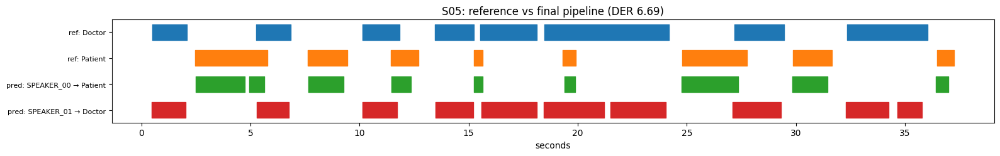

Doctor [00:00–00:02]: আসুন বসুন কী সমস্যা
Patient [00:02–00:05] (overlap): প্রস্রাবের সময় খুব জ্বালাপোড়া করে দুই দিন
Doctor [00:05–00:06] (overlap): জ্বর আছে কুমড়ো ব্যথা
Patient [00:07–00:09]: হালকা জ্বর আছে কোমড়ে না
Doctor [00:10–00:11] (overlap): বারবার প্রস্তাবের বেগ আছে
Patient [00:11–00:12] (overlap): জি অনেকবার
Doctor [00:13–00:15]: মনে হচ্ছে ইউরিন ইনফেকশন
Patient [00:15–00:15]: হম
Doctor [00:15–00:18] (overlap): একটা ইউরিন আর ইয়ার কালচার টেস্ট করাবেন
Doctor [00:18–00:21] (overlap): রিপোর্ট আসার আগ পর্যন্ত নাইট্রোফুরান্টয়েন
Doctor [00:21–00:24]: হান্ড্রেড মিলিগ্রাম দিনে দুইবার পাঁচ দিন
Patient [00:24–00:27] (overlap): আমার আগে একবার কিডনিতে পাথর হয়েছে
Doctor [00:27–00:29] (overlap): রাহুল একটা আলট্রাসাউন্ড ও করিয়ে নেবেন
Patient [00:29–00:31]: পানি কি বেশি খেতে হবে
Doctor [00:32–00:35]: দিনে অন্তত তিন লিটার পানি খাবেন রিপোর্ট নিয়ে আসবেন
Patient [00:36–00:36]: ঠিক আছে



### S06: fan noise
true roles: ['Attendant', 'Doctor', 'Patient'] | predicted: {'SPEAKER_00': 'Patient', 'SPEAKER_01': 'Doctor'} | role error 31.89 %

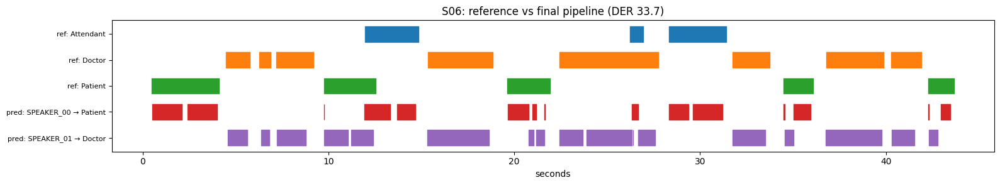

Patient [00:00–00:04]: ইসলাম আলিকুম ডাক্তার সাহেব প্রেশারের রিপোর্ট নিয়ে এসেছি
Doctor [00:04–00:05]: ওয়ালাইকুম আসালাম
Doctor [00:06–00:08]: দেখি ওষুধ ঠিকমতো খাচ্ছেন
Doctor [00:09–00:12] (overlap): জি অ্যামলোডিপিন ফাইভ মিলিগ্রাম সকালে
Patient [00:11–00:14] (overlap): বলে মাঝে মাঝে ভুলে যান আমি মনে করিয়ে দিই
Doctor [00:15–00:18]: আজকে প্রেশার একশো ষাট বাই একশো এখনও বেশি
Patient [00:19–00:20]: আমার মাঝে মাঝে মাথার
Patient [00:21–00:21]: যদি
Doctor [00:21–00:21]: ভার লাগে
Doctor [00:22–00:26]: অ্যামলোডি পিনের সাথে লোসার টান পঞ্চাশ মিলিগ্রাম যোগ করছি
Patient [00:26–00:26] (overlap): ছ
Doctor [00:26–00:27] (overlap): রাতে একটা
Patient [00:28–00:31]: উনি খুব লবণ খান ভাতের সাথে কাঁচা লবণ দেন
Doctor [00:31–00:33]: কাঁচা লবণ একদম বন্ধ
Doctor [00:34–00:35]: বিশেষজিকে
Patient [00:35–00:35]: কি আবার করতে হবে
Doctor [00:36–00:39]: হ্যাঁ একটা ইসিজি আর সিরাম ক্রিয়েটিনিন করাবেন
Doctor [00:40–00:41]: এক মাস পরে আসবেন
Doctor [00:42–00:42]: ঠিক আছে
Patient [00:42–00:43]: ধন্যবাদ



In [7]:
cases = {"S01": "patient speaks first", "S02": "silent patient, attendant speaks", "S03": "2 attendants + nurse + child",
         "S04": "3 speakers", "S05": "doctor interrupts (overlap)", "S06": "fan noise"}
ev = json.load(open(f"{NEW}/task3/tts_final_c1/eval.json", encoding="utf-8"))
for rec, case in cases.items():
    display(Markdown(f"### {rec}: {case}\ntrue roles: {sorted(ev[rec]['true_roles'].values())} | "
                     f"predicted: {ev[rec]['predicted_roles']} | role error {ev[rec]['role_error_rate%']} %"))
    display(Audio(f"{DATA}/tts_consultation/{rec}.wav"))
    timeline(f"{REPO}/data/tts_consultation/rttm/{rec}.rttm", f"{NEW}/task3/tts_final_c1/{rec}.rttm", ev[rec]["predicted_roles"],
             f"{rec}: reference vs final pipeline (DER {ev[rec]['DER%']})")
    print(open(f"{NEW}/task3/tts_final_c1/{rec}_transcript.txt", encoding="utf-8").read())

## 4. Model choice

- Diarization: community-1 (DiarBench test DER 19.8 → 16.7)
- ASR: IndicConformer 600M + VAD (lowest CER on real consultations, 7.2)

Everything runs on 16 kHz mono. The ASR runs on CPU (onnxruntime), pyannote on the GPU.
Main gap: drug, dose and test names are right only 71 % of the time (proposal in the report).

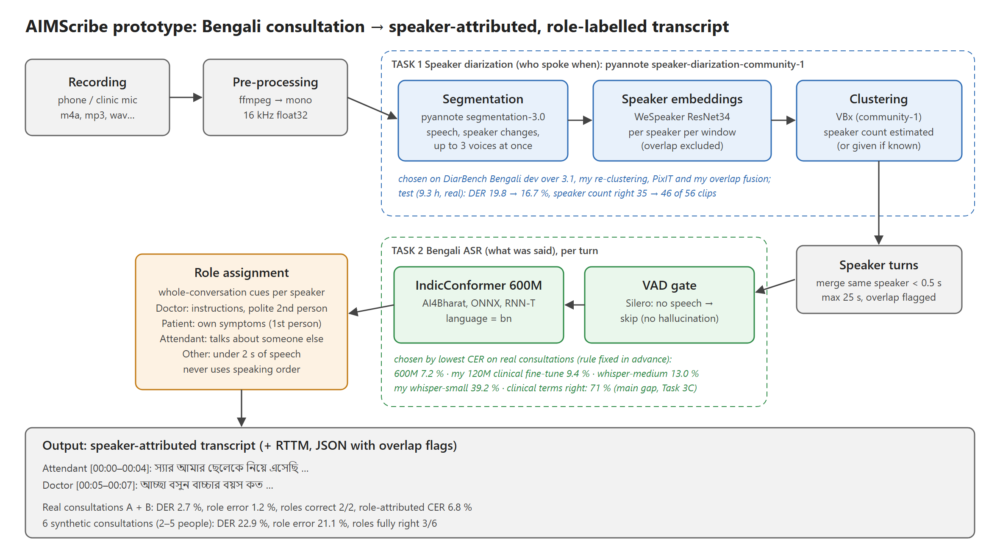

In [8]:
display(Image(f"{REPO}/report/system_diagram.png"))

## 5. Own recording

Upload any audio file. Set `NUM_SPEAKERS` if you know it.

In [9]:
from google.colab import files
NUM_SPEAKERS = None
up = files.upload()
for name in up:
    path = f"/content/{name}"
    shutil.move(name, path)
    extra = f"--num_speakers {NUM_SPEAKERS}" if NUM_SPEAKERS else ""
    sh(f"{P4} task3_pipeline/pipeline.py --asr_model {IC} --audio '{path}' --out_dir results/task3/my_audio {extra}", tail=60)

## Summary

All checks in one table. ✗ = outside the tolerance.

In [10]:
summary = pd.DataFrame(CHECKS)
print(f"{(summary.match == '✓').sum()} / {len(summary)} results reproduced within tolerance")
summary

19 / 19 results reproduced within tolerance


,result,submitted,reproduced,tolerance,match
0,consult A+B DER% (final pipeline),2.66,2.66,0.3,✓
1,consult A+B role_error_rate% (final pipeline),1.18,1.18,0.3,✓
2,consult A+B CER%_role_attributed (final pipeline),6.80,6.80,0.3,✓
3,consult A+B WER%_role_attributed (final pipeline),18.40,18.40,0.3,✓
4,consult A+B cpCER% (final pipeline),6.80,6.80,0.3,✓
5,consult_A: roles correct,1.00,1.00,0.0,✓
6,consult_B: roles correct,1.00,1.00,0.0,✓
7,"synthetic consultations DER%, tts_baseline",23.69,23.69,0.5,✓
8,"synthetic consultations role_error_rate%, tts_...",30.39,30.39,0.5,✓
9,"synthetic consultations cpCER%, tts_baseline",31.80,31.80,0.5,✓


## Download the outputs

In [11]:
paths = ['results/task3']
with zipfile.ZipFile('/content/outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for rel in paths:
        for p in [Path(REPO, rel)] if Path(REPO, rel).is_file() else Path(REPO, rel).rglob('*'):
            if p.is_file():
                z.write(p, p.relative_to(REPO))
    z.writestr('checks.csv', pd.DataFrame(CHECKS).to_csv(index=False))
from google.colab import files
files.download('/content/outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>